In [1]:
import logging
import os
from pathlib import Path
from dotenv import load_dotenv

# ==========================================
# 1. DEFINE PROJECT PATH
# ==========================================

# Parent folder of current working directory
project_dir = Path.cwd().parent

# Log directory
log_dir = project_dir / "log"
log_dir.mkdir(parents=True, exist_ok=True)

# Log file
log_file = log_dir / "app.log"

# Environment file
env_file = project_dir / ".env"

# ==========================================
# 2. CONFIGURE LOGGING
# ==========================================

logging.basicConfig(
    filename=log_file,
    filemode="a",
    format="%(asctime)s [%(levelname)s] %(message)s",
    level=logging.INFO,
    force=True
)

logging.info("Application started successfully")

# ==========================================
# 3. LOAD ENVIRONMENT VARIABLES
# ==========================================

if env_file.exists():
    load_dotenv(dotenv_path=env_file)
    logging.info(".env file loaded")
else:
    logging.warning(".env file not found: %s", env_file)

# ==========================================
# 4. GET GCP CONFIGURATION
# ==========================================

GCP_PROJECT_ID = os.getenv("GCP_PROJECT_ID")
BUCKET_NAME = os.getenv("BUCKET_NAME")
LOCATION = os.getenv("LOCATION")

# ==========================================
# 5. VALIDATE CONFIGURATION
# ==========================================

print("Project directory:", project_dir)
print("Log file:", log_file)
print("Environment file:", env_file)

print("GCP Project ID:", GCP_PROJECT_ID)
print("Bucket Name:", BUCKET_NAME)
print("Location:", LOCATION)

logging.info("Configuration loading completed")


Project directory: c:\Users\kikwe\Project Module 3\Group_9_Module_3_Project-main
Log file: c:\Users\kikwe\Project Module 3\Group_9_Module_3_Project-main\log\app.log
Environment file: c:\Users\kikwe\Project Module 3\Group_9_Module_3_Project-main\.env
GCP Project ID: None
Bucket Name: None
Location: None


In [2]:
logging.debug("Debug test")
logging.info("Info test")
logging.warning("Warning test")
logging.error("Error test")

In [3]:
import sys
print(sys.executable)

c:\Users\kikwe\anaconda3\python.exe


In [ ]:
# Data Ingestion

from pathlib import Path
import numpy as np
import pandas as pd
import yfinance as yf

# ==========================================
# 1. CREATE DATA DIRECTORY
# ==========================================

data_dir = Path("../data")
data_dir.mkdir(parents=True, exist_ok=True)

# ==========================================
# 2. DOWNLOAD HISTORICAL STOCK DATA
# ==========================================

df = yf.download(
    "SPY",
    start="2010-01-01",
    end="2026-10-15",
    auto_adjust=True,
    progress=False
)

if df.empty:
    raise ValueError("No SPY data downloaded")

if isinstance(df.columns, pd.MultiIndex):
    df.columns = df.columns.get_level_values(0)

df = df.sort_index().copy()

# ==========================================
# 3. FEATURE ENGINEERING
# ==========================================

close = df["Close"]

# Daily return
df["Daily_Return"] = close.pct_change()

# Simple moving averages
df["SMA_20"] = close.rolling(20).mean()
df["SMA_50"] = close.rolling(50).mean()

# Price relative to moving averages
df["Price_SMA20_Ratio"] = close / df["SMA_20"] - 1
df["Price_SMA50_Ratio"] = close / df["SMA_50"] - 1

# Historical daily volatility
df["Volatility_20"] = (
    df["Daily_Return"].rolling(20).std()
)

# ==========================================
# 4. RSI (WILDER SMOOTHING)
# ==========================================

delta = close.diff()

gain = delta.clip(lower=0)
loss = -delta.clip(upper=0)

# Wilder-style exponentially smoothed RSI
avg_gain = gain.ewm(
    alpha=1/14,
    adjust=False,
    min_periods=14
).mean()

avg_loss = loss.ewm(
    alpha=1/14,
    adjust=False,
    min_periods=14
).mean()

rs = avg_gain / avg_loss

df["RSI_14"] = 100 - 100 / (1 + rs)

# Handle zero-loss and flat-price cases
df.loc[(avg_loss == 0) & (avg_gain > 0),
       "RSI_14"] = 100
df.loc[(avg_loss == 0) & (avg_gain == 0),
       "RSI_14"] = 50

# ==========================================
# 5. CREATE PREDICTION TARGET
# ==========================================

# Predict next trading-day return
df["Target_Next_Return"] = (
    close.shift(-1) / close - 1
)

# Binary classification:
# 1 = Next day higher
# 0 = Next day unchanged or lower
df["Target_Up"] = (
    df["Target_Next_Return"] > 0
).astype(int)

# ==========================================
# 6. REMOVE MISSING TRAINING VALUES
# ==========================================

feature_cols = [
    "Daily_Return",
    "SMA_20",
    "SMA_50",
    "Price_SMA20_Ratio",
    "Price_SMA50_Ratio",
    "Volatility_20",
    "RSI_14"
]

df = df.replace([np.inf, -np.inf], np.nan)

df = df.dropna(
    subset=feature_cols + ["Target_Next_Return"]
)

# ==========================================
# 7. EXPORT CSV
# ==========================================

output_file = data_dir / "spy_features.csv"

df.to_csv(output_file, index_label="Date")

print(f"Saved: {output_file}")
print(f"Records: {len(df):,}")
print(f"Period: {df.index.min()} to {df.index.max()}")
print(df.tail())


Saved: ..\data\spy_features.csv
Records: 4,170
Period: 2010-03-16 00:00:00 to 2026-10-12 00:00:00
Price            Close        High         Low        Open    Volume  \
Date                                                                   
2026-10-06  779.090027  781.619995  777.960022  778.150024  36054300   
2026-10-07  777.219971  779.099976  773.609985  775.770020  30989200   
2026-10-08  773.929993  777.090027  770.440002  774.859985  40431100   
2026-10-09  778.570007  779.419983  775.140015  776.239990  22624500   
2026-10-12  778.099976  779.400024  777.049988  778.780029  18685000   

Price       Daily_Return      SMA_20      SMA_50  Price_SMA20_Ratio  \
Date                                                                  
2026-10-06      0.005498  765.058176  763.819869           0.018341   
2026-10-07     -0.002400  765.893597  764.583772           0.014788   
2026-10-08     -0.004233  766.792456  765.509309           0.009308   
2026-10-09      0.005995  767.601117  766.

In [5]:
#Target Definition & Class Imbalance

# Future 5-day return (using negative shift for the future target)
df["Future_Return_5d"] = df["Close"].pct_change(5).shift(-5)

def define_target(ret):
  if ret > 0.01:
  # Buy (Class 1)
    return 1
  elif ret < -0.01:
  # Sell (Class -1 or 2)
    return -1
  else:
  # Hold (Class 0)
    return 0

df["Target"] = df["Future_Return_5d"].apply(define_target)
df.dropna(inplace=True)

# Save the final dataset with targets included
final_output = data_dir / "spy_labeled_features.csv"
df.to_csv(final_output)

# Check class proportions
print(df["Target"].value_counts(normalize=True))

Target
 0    0.425210
 1    0.359904
-1    0.214886
Name: proportion, dtype: float64


In [6]:
from sklearn.model_selection import TimeSeriesSplit
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report

# Define features and target
feature_cols = ["Daily_Return", "SMA_20", "SMA_50", "Volatility_20", "RSI_14"]
X = df[feature_cols]
y = df["Target"]

# Time-series split (crucial to prevent look-ahead bias)
train_mask = df.index < "2023-01-01"
X_train, y_train = X[train_mask], y[train_mask]
X_test, y_test = X[~train_mask], y[~train_mask]

# Train model (class_weight="balanced" helps if classes are imbalanced)
model = RandomForestClassifier(n_estimators=100, class_weight="balanced", random_state=42)
model.fit(X_train, y_train)

# Evaluate
predictions = model.predict(X_test)
print(classification_report(y_test, predictions))

              precision    recall  f1-score   support

          -1       0.20      0.73      0.32       191
           0       0.46      0.18      0.26       392
           1       0.44      0.11      0.18       359

    accuracy                           0.27       942
   macro avg       0.37      0.34      0.25       942
weighted avg       0.40      0.27      0.24       942



In [7]:
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score

feature_cols = ["Daily_Return", "SMA_20", "SMA_50", "Volatility_20", "RSI_14"]
X = df[feature_cols]
y = df["Target"]

split_date = pd.Timestamp("2023-01-01")
train_positions = np.flatnonzero(df.index < split_date)
test_positions = np.flatnonzero(df.index >= split_date)

# Exclude the final five training rows because their targets look into the test period
train_positions = train_positions[:-5]

X_train, y_train = X.iloc[train_positions], y.iloc[train_positions]
X_test, y_test = X.iloc[test_positions], y.iloc[test_positions]

model = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",
    random_state=42
)
model.fit(X_train, y_train)

predictions = model.predict(X_test)

print("Model accuracy:", accuracy_score(y_test, predictions))
print(classification_report(y_test, predictions))

# Compare against predicting the most common training class every time
baseline_class = y_train.mode().iloc[0]
baseline_predictions = np.full(len(y_test), baseline_class)
print("Baseline accuracy:", accuracy_score(y_test, baseline_predictions))

Model accuracy: 0.2643312101910828
              precision    recall  f1-score   support

          -1       0.21      0.80      0.33       191
           0       0.55      0.15      0.23       392
           1       0.40      0.11      0.17       359

    accuracy                           0.26       942
   macro avg       0.39      0.35      0.24       942
weighted avg       0.42      0.26      0.23       942

Baseline accuracy: 0.416135881104034


In [8]:
import pandas as pd
from sklearn.model_selection import TimeSeriesSplit
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score

feature_cols = ["Daily_Return", "SMA_20", "SMA_50", "Volatility_20", "RSI_14"]
X = df[feature_cols]
y = df["Target"]

# The five-row gap prevents five-day target windows from crossing each split.
splitter = TimeSeriesSplit(n_splits=5, gap=5)
results = []

for fold, (train_idx, test_idx) in enumerate(splitter.split(X), start=1):
    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

    model = RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced",
        random_state=42
    )
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    baseline_class = y_train.mode().iloc[0]
    baseline_predictions = [baseline_class] * len(y_test)

    results.append({
        "fold": fold,
        "test_start": df.index[test_idx[0]].date(),
        "test_end": df.index[test_idx[-1]].date(),
        "model_accuracy": accuracy_score(y_test, predictions),
        "baseline_accuracy": accuracy_score(y_test, baseline_predictions),
        "model_balanced_accuracy": balanced_accuracy_score(y_test, predictions),
        "model_macro_f1": f1_score(y_test, predictions, average="macro", zero_division=0),
    })

results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))
print("\nAverage scores:")
print(results_df.select_dtypes("number").mean())

 fold test_start   test_end  model_accuracy  baseline_accuracy  model_balanced_accuracy  model_macro_f1
    1 2012-12-17 2015-09-18        0.231988           0.324207                 0.359474        0.176632
    2 2015-09-21 2018-06-21        0.342939           0.554755                 0.304507        0.305914
    3 2018-06-22 2021-03-25        0.226225           0.355908                 0.315068        0.171173
    4 2021-03-26 2023-12-27        0.348703           0.373199                 0.337904        0.317236
    5 2023-12-28 2026-10-05        0.270893           0.417867                 0.357985        0.252157

Average scores:
fold                       3.000000
model_accuracy             0.284150
baseline_accuracy          0.405187
model_balanced_accuracy    0.334988
model_macro_f1             0.244622
dtype: float64


In [9]:
feature_cols = [
    "Daily_Return",
    "Price_SMA20_Ratio",
    "Price_SMA50_Ratio",
    "Volatility_20",
    "RSI_14",
]

In [10]:
import numpy as np
import pandas as pd
from sklearn.model_selection import TimeSeriesSplit
from sklearn.ensemble import RandomForestClassifier

feature_cols = [
    "Daily_Return",
    "Price_SMA20_Ratio",
    "Price_SMA50_Ratio",
    "Volatility_20",
    "RSI_14",
]
X = df[feature_cols]
y = df["Target"]

splitter = TimeSeriesSplit(n_splits=5, gap=5)
oof_predictions = pd.Series(np.nan, index=X.index)
for train_idx, test_idx in splitter.split(X):
    model = RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced",
        random_state=42,
    )
    model.fit(X.iloc[train_idx], y.iloc[train_idx])
    oof_predictions.iloc[test_idx] = model.predict(X.iloc[test_idx])

trade_positions = np.flatnonzero(oof_predictions.notna().to_numpy())[::5]
signals = oof_predictions.iloc[trade_positions].astype(int).to_numpy()
future_returns = df["Future_Return_5d"].iloc[trade_positions].to_numpy()
cost_per_side = 0.0005

def simulate_long_cash(actions, period_returns):
    portfolio_returns = []
    invested = 0
    for action, market_return in zip(actions, period_returns):
        target_position = 1 if action == 1 else 0 if action == -1 else invested
        turnover = abs(target_position - invested)
        net_return = (1 + target_position * market_return) * (1 - cost_per_side) ** turnover - 1
        portfolio_returns.append(net_return)
        invested = target_position
    if portfolio_returns and invested:
        portfolio_returns[-1] = (1 + portfolio_returns[-1]) * (1 - cost_per_side) - 1
    return np.asarray(portfolio_returns)

strategy_returns = simulate_long_cash(signals, future_returns)
buy_hold_returns = simulate_long_cash(
    np.ones(len(future_returns), dtype=int), future_returns
)
print(f"Out-of-sample periods: {len(trade_positions)}")
print("BUY enters/maintains long; SELL exits to cash; HOLD retains the current position.")
print(f"Illustrative cost: {cost_per_side:.2%} per side")
print(f"Model strategy compounded return: {np.prod(1 + strategy_returns) - 1:.2%}")
print(f"Buy-and-hold compounded return: {np.prod(1 + buy_hold_returns) - 1:.2%}")


Out-of-sample periods: 694
BUY enters/maintains long; SELL exits to cash; HOLD retains the current position.
Illustrative cost: 0.05% per side
Model strategy compounded return: 364.61%
Buy-and-hold compounded return: 588.23%


In [14]:
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import TimeSeriesSplit

feature_cols = [
    "Daily_Return",
    "Price_SMA20_Ratio",
    "Price_SMA50_Ratio",
    "Volatility_20",
    "RSI_14",
]
X = df[feature_cols]
y = df["Target"]

# Generate out-of-fold predictions; each prediction is from a model that did not train on that date.
oof_predictions = pd.Series(np.nan, index=X.index)
splitter = TimeSeriesSplit(n_splits=5, gap=5)
for fold, (train_idx, test_idx) in enumerate(splitter.split(X)):
    from sklearn.model_selection import GridSearchCV

parameter_grid = {
    "n_estimators": [200, 400],
    "max_depth": [4, 8, None],
    "min_samples_leaf": [5, 20],
    "max_features": ["sqrt", 0.8],
}

for fold, (train_idx, test_idx) in enumerate(splitter.split(X)):
    search = GridSearchCV(
        RandomForestClassifier(
            class_weight="balanced",
            random_state=42,
        ),
        param_grid=parameter_grid,
        cv=TimeSeriesSplit(n_splits=3, gap=5),
        scoring="balanced_accuracy",
        n_jobs=-1,
    )
    search.fit(X.iloc[train_idx], y.iloc[train_idx])

    model = search.best_estimator_
    oof_predictions.iloc[test_idx] = model.predict(X.iloc[test_idx])
    #params = results[fold]["best_parameters"]
    model = RandomForestClassifier(
       # **params,
        class_weight="balanced",
        random_state=42,
    )
    model.fit(X.iloc[train_idx], y.iloc[train_idx])
    oof_predictions.iloc[test_idx] = model.predict(X.iloc[test_idx])

# Sample non-overlapping five-trading-day return periods.
positions = np.flatnonzero(oof_predictions.notna().to_numpy())[::5]
signals = oof_predictions.iloc[positions].astype(int).to_numpy()
future_returns = df["Future_Return_5d"].iloc[positions].to_numpy()
cost_per_side = 0.0005

def simulate_long_cash(actions, period_returns):
    """Apply BUY/SELL/HOLD actions, charging costs when position changes."""
    portfolio_returns = []
    invested = 0
    for action, market_return in zip(actions, period_returns):
        if action == 1:
            target_position = 1
        elif action == -1:
            target_position = 0
        else:
            target_position = invested
        turnover = abs(target_position - invested)
        net_return = (
            (1 + target_position * market_return)
            * (1 - cost_per_side) ** turnover
            - 1
        )
        portfolio_returns.append(net_return)
        invested = target_position
    if portfolio_returns and invested:
        portfolio_returns[-1] = (
            (1 + portfolio_returns[-1]) * (1 - cost_per_side) - 1
        )
    return np.asarray(portfolio_returns)

# Rule benchmark: buy in an uptrend and exit when any trend condition reverses.
close = df["Close"]
macd_line = close.ewm(span=12, adjust=False).mean() - close.ewm(
    span=26, adjust=False
).mean()
macd_signal = macd_line.ewm(span=9, adjust=False).mean()
sampled_close = close.iloc[positions].to_numpy()
sampled_sma50 = df["SMA_50"].iloc[positions].to_numpy()
sampled_rsi = df["RSI_14"].iloc[positions].to_numpy()
sampled_macd = macd_line.iloc[positions].to_numpy()
sampled_macd_signal = macd_signal.iloc[positions].to_numpy()
rule_buy = (
    (sampled_close > sampled_sma50)
    & (sampled_rsi > 50)
    & (sampled_macd > sampled_macd_signal)
)
rule_sell = (
    (sampled_close < sampled_sma50)
    | (sampled_rsi < 50)
    | (sampled_macd < sampled_macd_signal)
)
rule_actions = np.where(rule_buy, 1, np.where(rule_sell, -1, 0))

model_returns = simulate_long_cash(signals, future_returns)
rule_returns = simulate_long_cash(rule_actions, future_returns)
buy_hold_returns = simulate_long_cash(
    np.ones(len(future_returns), dtype=int), future_returns
)

def summarize_strategy(name, returns):
    equity = np.concatenate(([1.0], np.cumprod(1 + returns)))
    drawdown = equity / np.maximum.accumulate(equity) - 1
    return {
        "strategy": name,
        "compounded_return": equity[-1] - 1,
        "max_drawdown": drawdown.min(),
    }

summary = pd.DataFrame([
    summarize_strategy("Random Forest (long-or-cash)", model_returns),
    summarize_strategy("RSI/MACD/SMA rules (long-or-cash)", rule_returns),
    summarize_strategy("Buy and hold", buy_hold_returns),
])
print(f"Out-of-sample five-day periods: {len(positions)}")
print(f"Illustrative transaction cost: {cost_per_side:.2%} per side")
print("HOLD retains the prior position; SELL exits to cash; short positions are not used.")
print(summary.to_string(index=False, formatters={
    "compounded_return": "{:.2%}".format,
    "max_drawdown": "{:.2%}".format,
}))


Out-of-sample five-day periods: 694
Illustrative transaction cost: 0.05% per side
HOLD retains the prior position; SELL exits to cash; short positions are not used.
                         strategy compounded_return max_drawdown
     Random Forest (long-or-cash)           364.61%      -29.81%
RSI/MACD/SMA rules (long-or-cash)            81.41%      -14.58%
                     Buy and hold           588.23%      -28.72%


Strategy max drawdown: -29.81%
Buy-and-hold max drawdown: -28.72%


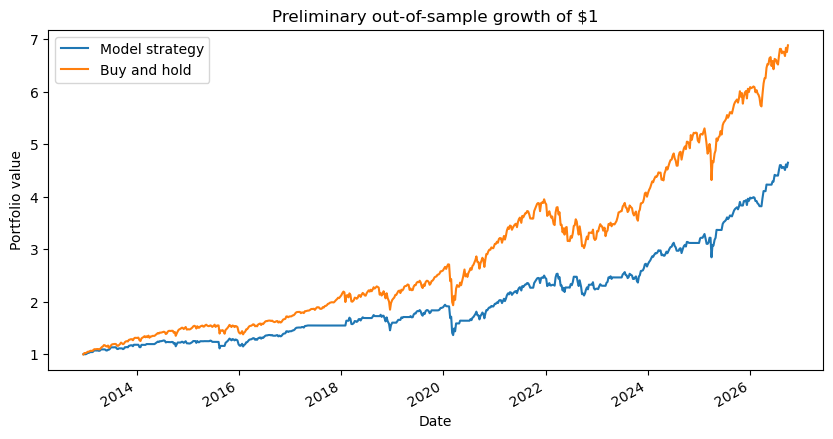

In [15]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

dates = df.index[trade_positions]
strategy_equity = pd.Series(
    np.cumprod(1 + strategy_returns), index=dates, name="Model strategy"
)
benchmark_equity = pd.Series(
    np.cumprod(1 + buy_hold_returns), index=dates, name="Buy and hold"
)
strategy_drawdown = strategy_equity / strategy_equity.cummax() - 1
benchmark_drawdown = benchmark_equity / benchmark_equity.cummax() - 1
print(f"Strategy max drawdown: {strategy_drawdown.min():.2%}")
print(f"Buy-and-hold max drawdown: {benchmark_drawdown.min():.2%}")
pd.concat([strategy_equity, benchmark_equity], axis=1).plot(
    title="Preliminary out-of-sample growth of $1", figsize=(10, 5)
)
plt.ylabel("Portfolio value")
plt.show()


## Preliminary simulation

This initial model-only simulation is superseded by the tuned model and rule-based benchmark comparison at the end of the notebook.


The preliminary single-model results above are superseded by the final out-of-sample comparison below. Use the latest rerun of the final backtest cell for the project conclusion.


In [ ]:
for path in [output_file, final_output]:
    print(f"{path.resolve()} — {'OK' if path.exists() else 'MISSING'}")

if final_output.exists():
    labeled = pd.read_csv(final_output, index_col="Date", parse_dates=True)
    print(f"\nLabeled records: {len(labeled):,}")
    print("Target counts:")
    print(labeled["Target"].value_counts().sort_index())

C:\Users\kikwe\Project Module 3\Group_9_Module_3_Project-main\data\spy_features.csv — OK
C:\Users\kikwe\Project Module 3\Group_9_Module_3_Project-main\data\spy_labeled_features.csv — OK

Labeled records: 3,969
Target counts:
Target
-1     851
 0    1683
 1    1435
Name: count, dtype: int64


In [ ]:
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import balanced_accuracy_score, accuracy_score
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit

feature_cols = [
    "Daily_Return",
    "Price_SMA20_Ratio",
    "Price_SMA50_Ratio",
    "Volatility_20",
    "RSI_14",
]

X = df[feature_cols]
y = df["Target"]

parameter_grid = {
    "n_estimators": [200, 400],
    "max_depth": [4, 8, None],
    "min_samples_leaf": [5, 20],
    "max_features": ["sqrt", 0.8],
}

outer_cv = TimeSeriesSplit(n_splits=5, gap=5)
results = []

for fold, (train_idx, test_idx) in enumerate(outer_cv.split(X), start=1):
    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

    search = GridSearchCV(
        estimator=RandomForestClassifier(
            class_weight="balanced",
            random_state=42,
        ),
        param_grid=parameter_grid,
        cv=TimeSeriesSplit(n_splits=3, gap=5),
        scoring="balanced_accuracy",
        n_jobs=-1,
    )
    search.fit(X_train, y_train)

    predictions = search.predict(X_test)
    baseline = [y_train.mode().iloc[0]] * len(y_test)

    results.append({
        "fold": fold,
        "tuned_balanced_accuracy":
            balanced_accuracy_score(y_test, predictions),
        "baseline_balanced_accuracy":
            balanced_accuracy_score(y_test, baseline),
        "tuned_accuracy": accuracy_score(y_test, predictions),
        "best_parameters": search.best_params_,
    })

results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))
print("\nMean scores:")
print(results_df[[
    "tuned_balanced_accuracy",
    "baseline_balanced_accuracy",
    "tuned_accuracy",
]].mean())

 fold  tuned_balanced_accuracy  baseline_balanced_accuracy  tuned_accuracy                                                                       best_parameters
    1                 0.331651                    0.333333        0.316188    {'max_depth': 4, 'max_features': 0.8, 'min_samples_leaf': 20, 'n_estimators': 400}
    2                 0.414905                    0.333333        0.476551  {'max_depth': 4, 'max_features': 'sqrt', 'min_samples_leaf': 5, 'n_estimators': 400}
    3                 0.346026                    0.333333        0.364599     {'max_depth': 4, 'max_features': 0.8, 'min_samples_leaf': 5, 'n_estimators': 400}
    4                 0.419774                    0.333333        0.434191     {'max_depth': 4, 'max_features': 0.8, 'min_samples_leaf': 5, 'n_estimators': 400}
    5                 0.417850                    0.333333        0.459909 {'max_depth': 8, 'max_features': 'sqrt', 'min_samples_leaf': 20, 'n_estimators': 400}

Mean scores:
tuned_balanced_accur

In [ ]:
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import TimeSeriesSplit

feature_cols = [
    "Daily_Return",
    "Price_SMA20_Ratio",
    "Price_SMA50_Ratio",
    "Volatility_20",
    "RSI_14",
]
X = df[feature_cols]
y = df["Target"]

# Generate out-of-fold predictions; each prediction is from a model that did not train on that date.
oof_predictions = pd.Series(np.nan, index=X.index)
splitter = TimeSeriesSplit(n_splits=5, gap=5)
for fold, (train_idx, test_idx) in enumerate(splitter.split(X)):
    params = results[fold]["best_parameters"]
    model = RandomForestClassifier(
        **params,
        class_weight="balanced",
        random_state=42,
    )
    model.fit(X.iloc[train_idx], y.iloc[train_idx])
    oof_predictions.iloc[test_idx] = model.predict(X.iloc[test_idx])

# Sample non-overlapping five-trading-day return periods.
positions = np.flatnonzero(oof_predictions.notna().to_numpy())[::5]
signals = oof_predictions.iloc[positions].astype(int).to_numpy()
future_returns = df["Future_Return_5d"].iloc[positions].to_numpy()
cost_per_side = 0.0005

def simulate_long_cash(actions, period_returns):
    """Apply BUY/SELL/HOLD actions, charging costs when position changes."""
    portfolio_returns = []
    invested = 0
    for action, market_return in zip(actions, period_returns):
        if action == 1:
            target_position = 1
        elif action == -1:
            target_position = 0
        else:
            target_position = invested
        turnover = abs(target_position - invested)
        net_return = (
            (1 + target_position * market_return)
            * (1 - cost_per_side) ** turnover
            - 1
        )
        portfolio_returns.append(net_return)
        invested = target_position
    if portfolio_returns and invested:
        portfolio_returns[-1] = (
            (1 + portfolio_returns[-1]) * (1 - cost_per_side) - 1
        )
    return np.asarray(portfolio_returns)

# Rule benchmark: buy in an uptrend and exit when any trend condition reverses.
close = df["Close"]
macd_line = close.ewm(span=12, adjust=False).mean() - close.ewm(
    span=26, adjust=False
).mean()
macd_signal = macd_line.ewm(span=9, adjust=False).mean()
sampled_close = close.iloc[positions].to_numpy()
sampled_sma50 = df["SMA_50"].iloc[positions].to_numpy()
sampled_rsi = df["RSI_14"].iloc[positions].to_numpy()
sampled_macd = macd_line.iloc[positions].to_numpy()
sampled_macd_signal = macd_signal.iloc[positions].to_numpy()
rule_buy = (
    (sampled_close > sampled_sma50)
    & (sampled_rsi > 50)
    & (sampled_macd > sampled_macd_signal)
)
rule_sell = (
    (sampled_close < sampled_sma50)
    | (sampled_rsi < 50)
    | (sampled_macd < sampled_macd_signal)
)
rule_actions = np.where(rule_buy, 1, np.where(rule_sell, -1, 0))

model_returns = simulate_long_cash(signals, future_returns)
rule_returns = simulate_long_cash(rule_actions, future_returns)
buy_hold_returns = simulate_long_cash(
    np.ones(len(future_returns), dtype=int), future_returns
)

def summarize_strategy(name, returns):
    equity = np.concatenate(([1.0], np.cumprod(1 + returns)))
    drawdown = equity / np.maximum.accumulate(equity) - 1
    return {
        "strategy": name,
        "compounded_return": equity[-1] - 1,
        "max_drawdown": drawdown.min(),
    }

summary = pd.DataFrame([
    summarize_strategy("Random Forest (long-or-cash)", model_returns),
    summarize_strategy("RSI/MACD/SMA rules (long-or-cash)", rule_returns),
    summarize_strategy("Buy and hold", buy_hold_returns),
])
print(f"Out-of-sample five-day periods: {len(positions)}")
print(f"Illustrative transaction cost: {cost_per_side:.2%} per side")
print("HOLD retains the prior position; SELL exits to cash; short positions are not used.")
print(summary.to_string(index=False, formatters={
    "compounded_return": "{:.2%}".format,
    "max_drawdown": "{:.2%}".format,
}))


Out-of-sample five-day periods: 661
Illustrative transaction cost: 0.05% per side
HOLD retains the prior position; SELL exits to cash; short positions are not used.
                         strategy compounded_return max_drawdown
     Random Forest (long-or-cash)           163.40%      -16.94%
RSI/MACD/SMA rules (long-or-cash)            82.86%      -13.93%
                     Buy and hold           506.98%      -29.07%


## Conclusion

Use the current output of the preceding final backtest cell to compare the tuned Random Forest, the RSI/MACD/SMA rule-based strategy, and buy-and-hold. All strategies use the same non-overlapping five-trading-day periods, long-or-cash exposure, and illustrative 0.05% per-side transaction costs. BUY enters or maintains a long position, SELL exits to cash, and HOLD leaves the existing position unchanged. These simplified historical results do not establish future performance or constitute investment advice.
